In [66]:
class ArithDict:
    __slots__ = ('_d',)

    def __init__(self, data=None):
        self._d = {}

        if data is None:
            return

        # Mapping: {'a': 3, 'b': -1}
        if hasattr(data, 'items'):
            for k, v in data.items():
                v = int(v)
                if v != 0:
                    self._d[k] = v
            return

        # Iterable of keys: ['a', 'b', 'a']
        for k in data:
            self._d[k] = self._d.get(k, 0) + 1
            if self._d[k] == 0:
                del self._d[k]

    # --- dict behavior ---
    def __getitem__(self, k):
        return self._d.get(k, 0)

    def __setitem__(self, k, v):
        v = int(v)
        if v == 0:
            self._d.pop(k, None)
        else:
            self._d[k] = v

    def __delitem__(self, k):
        self._d.pop(k, None)

    def __iter__(self):
        return iter(self._d)

    def __len__(self):
        return len(self._d)

    def items(self):
        return self._d.items()

    def to_dict(self):
        return dict(self._d)

    # --- arithmetic ---
    def _combine(self, other, op):
        out = {}
        keys = set(self._d) | set(other)
        for k in keys:
            v = op(self[k], other.get(k, 0))
            if v != 0:
                out[k] = v
        return ArithDict(out)

    def __add__(self, other):
        return self._combine(other, lambda a, b: a + b)

    def __sub__(self, other):
        return self._combine(other, lambda a, b: a - b)

    def __iadd__(self, other):
        for k in set(self._d) | set(other):
            v = self[k] + other.get(k, 0)
            if v == 0:
                self._d.pop(k, None)
            else:
                self._d[k] = v
        return self

    def __isub__(self, other):
        for k in set(self._d) | set(other):
            v = self[k] - other.get(k, 0)
            if v == 0:
                self._d.pop(k, None)
            else:
                self._d[k] = v
        return self

    def __neg__(self):
        return ArithDict({k: -v for k, v in self._d.items()})

    def __mul__(self, scalar):
        if not isinstance(scalar, int):
            return NotImplemented
        if scalar == 0:
            return ArithDict()
        return ArithDict({k: v * scalar for k, v in self._d.items()})

    __rmul__ = __mul__

    def __repr__(self):
        return f'ArithDict({self._d})'

    def get(self, k, default=0):
        return self._d.get(k, default)

    def keys(self):
        return self._d.keys()

    def values(self):
        return self._d.values()

In [28]:
import h3
from h3coco import cells_for_state
import h3coco
from dataclasses import dataclass

target_cells = cells_for_state('california', 7)

In [30]:
'8049fffffffffff'
'81483ffffffffff'
'824807fffffffff'

cells = (set(h3.cell_to_children('8049fffffffffff', 2)) - set(h3.cell_to_children('81483ffffffffff')) ) | {'824807fffffffff'}

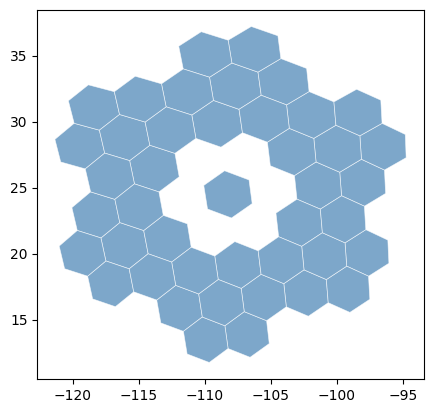

In [31]:
h3coco.plot_cells(cells)

In [36]:
@dataclass
class Janus:
    h: str
    res: int
    local_target_cells: set[str]
    pos: dict[str, int]
    neg: dict[str, int]
    
    def check(self):
        for h in self.local_target_cells:
            assert h3.get_resolution(h) == self.res

        assert self.local_target_cells <= set(h3.cell_to_children(self.h, self.res))

In [37]:
jan = Janus(
    h = '8049fffffffffff',
    res = 2,
    local_target_cells = (set(h3.cell_to_children('8049fffffffffff', 2)) - set(h3.cell_to_children('81483ffffffffff')) ) | {'824807fffffffff'},
    pos = {'8049fffffffffff': 1, '81483ffffffffff': -1, '824807fffffffff': 1},
    neg = {'81483ffffffffff': 1, '824807fffffffff': -1},
)

jan.check()

In [61]:
d = ArithDict()
d['a'] = -1
-d

ArithDict({'a': 1})

In [52]:
from collections import Counter
c = Counter()
c['a'] = -1
c + c

Counter()

Counter()

In [83]:
def co_uncompact(cells: dict[str, int], res: int) -> set[str]:
    ad = ArithDict()
    for h, sign in cells.items():
        d = h3.cell_to_children(h, res)
        ad += sign*ArithDict(d)

    for k,v in ad.items():
        assert v == 1
        assert h3.get_resolution(k) == res

    out = set(ad.keys())
    assert len(out) == len(ad)
    
    return out

In [84]:
# complement. unpack. counter?

co_uncompact(jan.pos, 2)

{'824807fffffffff',
 '824847fffffffff',
 '82484ffffffffff',
 '824857fffffffff',
 '82485ffffffffff',
 '824867fffffffff',
 '82486ffffffffff',
 '824877fffffffff',
 '824887fffffffff',
 '82488ffffffffff',
 '824897fffffffff',
 '82489ffffffffff',
 '8248a7fffffffff',
 '8248affffffffff',
 '8248b7fffffffff',
 '8248c7fffffffff',
 '8248cffffffffff',
 '8248d7fffffffff',
 '8248dffffffffff',
 '8248e7fffffffff',
 '8248effffffffff',
 '8248f7fffffffff',
 '824907fffffffff',
 '82490ffffffffff',
 '824917fffffffff',
 '82491ffffffffff',
 '824927fffffffff',
 '82492ffffffffff',
 '824937fffffffff',
 '824947fffffffff',
 '82494ffffffffff',
 '824957fffffffff',
 '82495ffffffffff',
 '824967fffffffff',
 '82496ffffffffff',
 '824977fffffffff',
 '824987fffffffff',
 '82498ffffffffff',
 '824997fffffffff',
 '82499ffffffffff',
 '8249a7fffffffff',
 '8249affffffffff',
 '8249b7fffffffff'}

In [18]:
len(target)

74445

In [15]:
best_pos_under = {
    c: {c: 1}
    for c in cells
}

def up(best_pos_under, all_cells):
    parents = set(
        h3.cell_to_parent(c)
        for c in cells
    )
    for p in parents:
        children = set(h3.cell_to_children(p))
        pos_children = cells & children
    

In [12]:
cells = set(cells)

parents = set(
    h3.cell_to_parent(c)
    for c in cells
)

pos = {}
neg = {}
for p in parents:
    children = set(h3.cell_to_children(p))
    pos_children = children & cells
    neg_children = children - cells
    assert children == pos_children | neg_children
    if len(pos_children) <= 4:
        pos[p] = pos_children
        neg[p] = 
    else:
        